## Projeto de ICD - Desempenho acadêmico de estudantes

---


Feito por Felipe Damasceno, Luis Emediato, Mateus Antinossi e Raiza Wunsch

##Introdução

Esse trabalho busca analisar os principais fatores que impactam o desempenho acadêmico de estudantes, medido pela nota na prova. A base de dados utilizada é a "Student Performance Factors", obtida no site Kaggle. Nosso primeiro trabalho foi importar os dados e tratá-los. Separamos em variáveis explicativas e em variável resposta, além de normalizar os dados e criar splits de treino e teste.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import multiprocessing
import itertools
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from math import pi
import scipy.stats as stats
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.linear_model import LassoCV



In [ ]:
student_performance_df = pd.read_csv('https://raw.githubusercontent.com/felapas/TP-ICD-data/refs/heads/main/StudentPerformanceFactors.csv')

student_performance_df = student_performance_df.dropna()
student_performance_df.head()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
print(student_performance_df.shape)

(6378, 20)


In [ ]:
Y = student_performance_df['Exam_Score']
Z = student_performance_df.drop('Exam_Score', axis=1)
numerical_cols = Z.select_dtypes(include=['number']).columns.tolist()
categorical_cols = Z.select_dtypes(include=['object', 'category']).columns.tolist()
scaler = StandardScaler()
Z_scaled_numerical = pd.DataFrame(scaler.fit_transform(Z[numerical_cols]), columns=numerical_cols, index=Z.index)
Z_encoded_categorical = pd.get_dummies(Z[categorical_cols], columns=categorical_cols, drop_first=True)
Z_processed = pd.concat([Z_scaled_numerical, Z_encoded_categorical], axis=1) # df z normalizado e processado com as dummies

Z_train, Z_test, y_train, y_test = train_test_split(Z_processed, Y, test_size = 0.3, random_state = 42) # Separando em teste e treino

# Análise exploratória
### Primeiro, gostaríamos de entender a base de dados que vamos utilizar. Para isso, utilizamos gráficos de diversas variáveis numéricas.

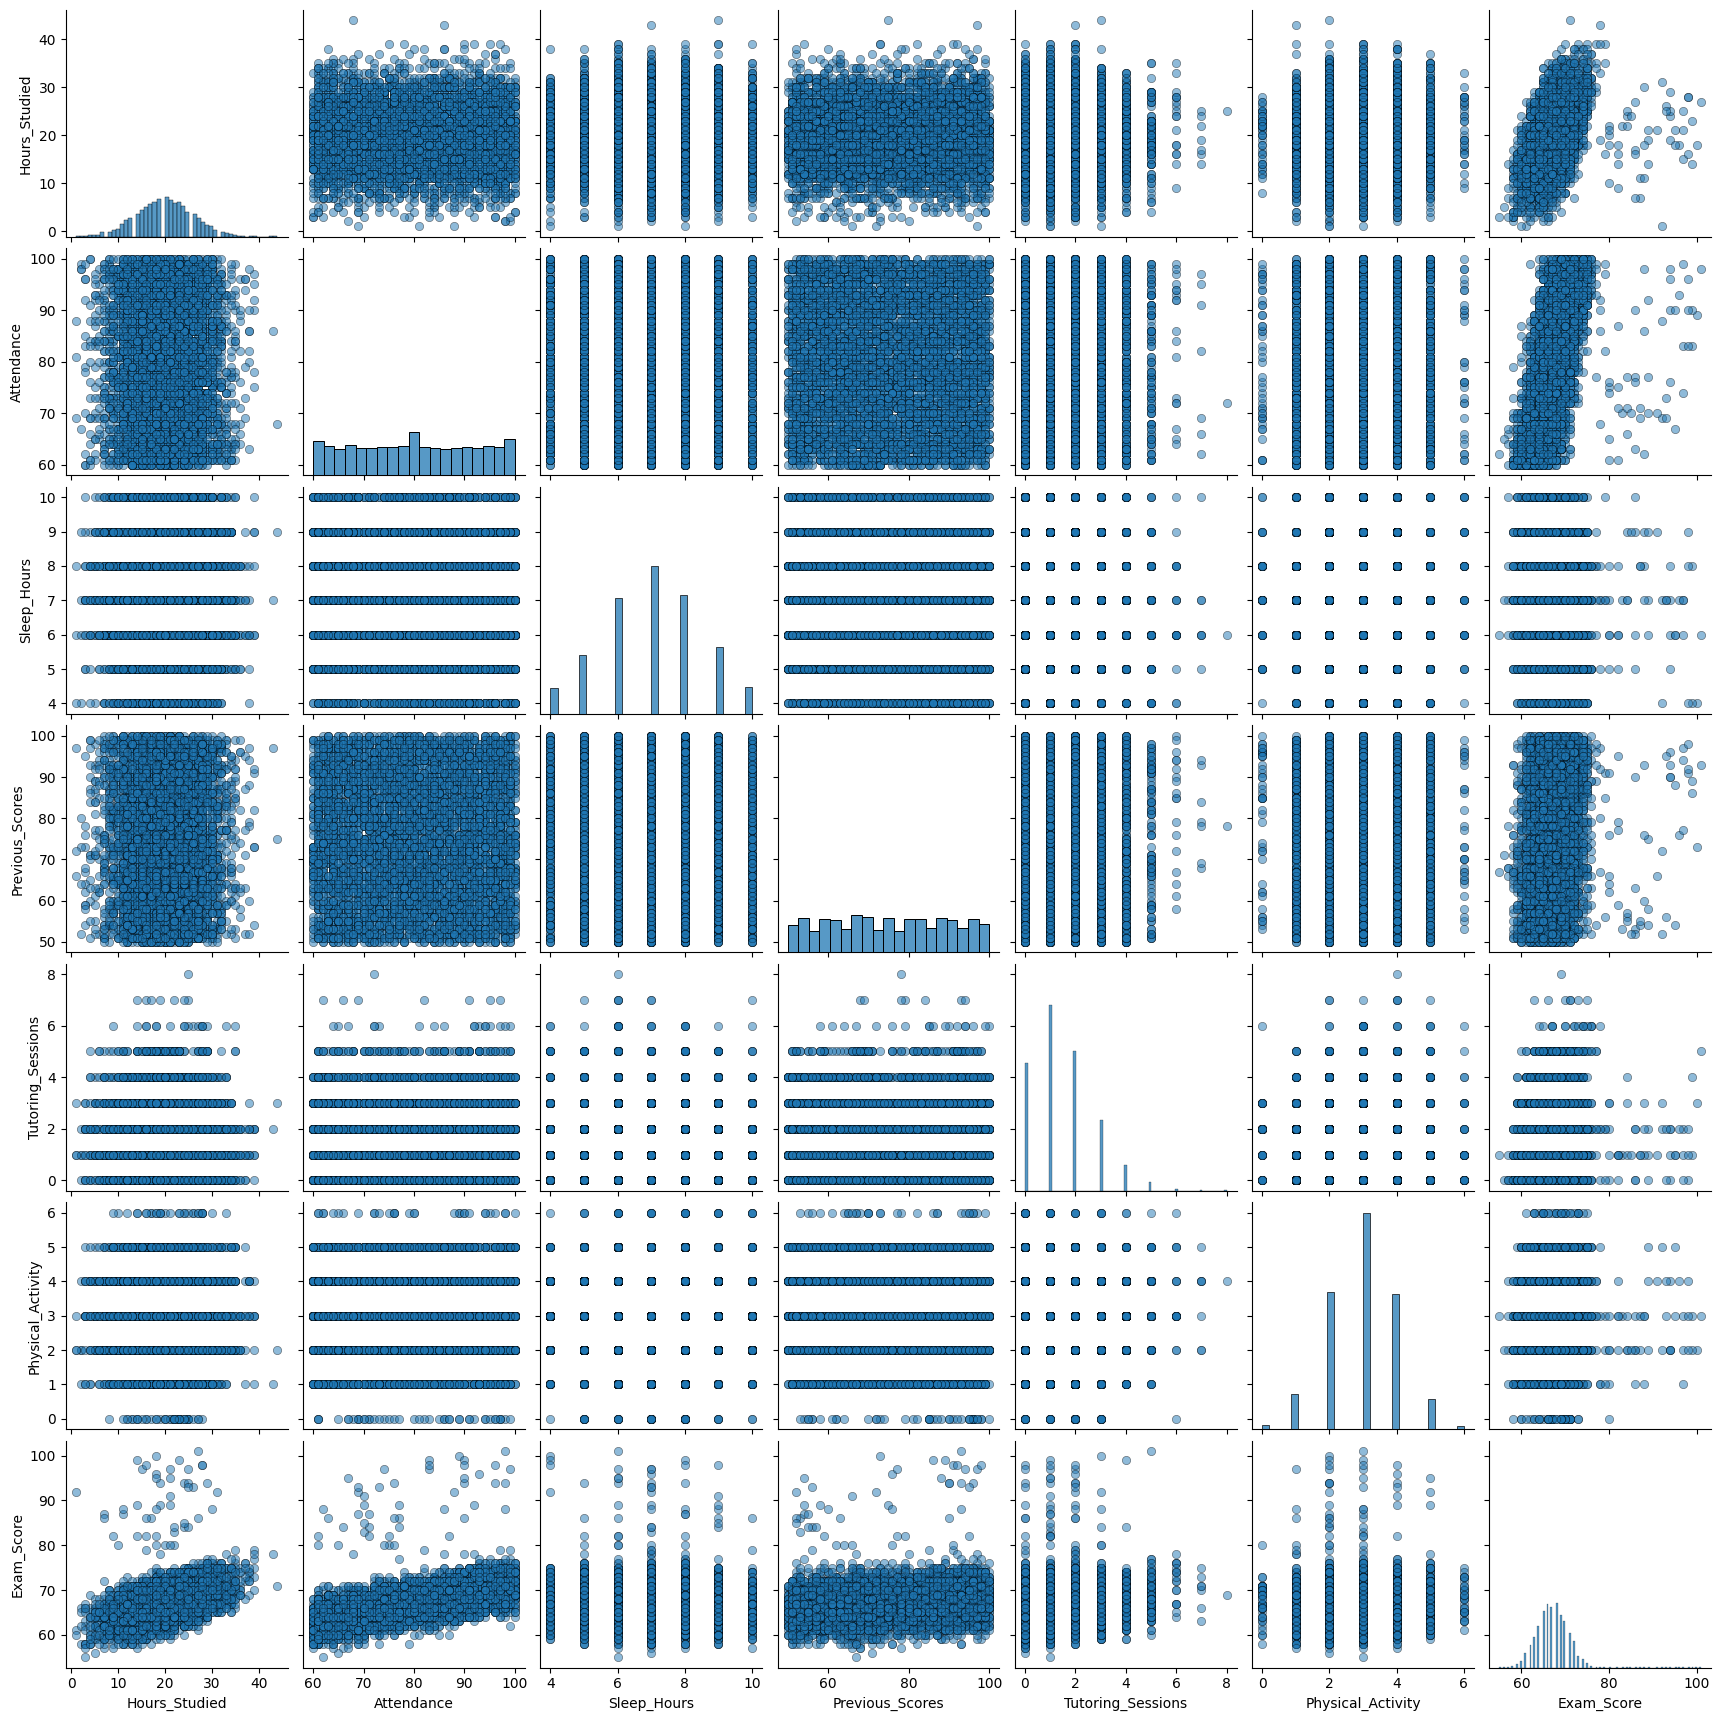

In [ ]:

sns.pairplot(student_performance_df, diag_kws={'edgecolor':'k'}, plot_kws={'alpha':0.5, 'edgecolor':'k'})

A última linha nos dá uma ideia melhor de quais variáveis numéricas têm influência. Aparentemente, elas são horas de estudo e comparecimento nas aulas. As ideias iniciais são:

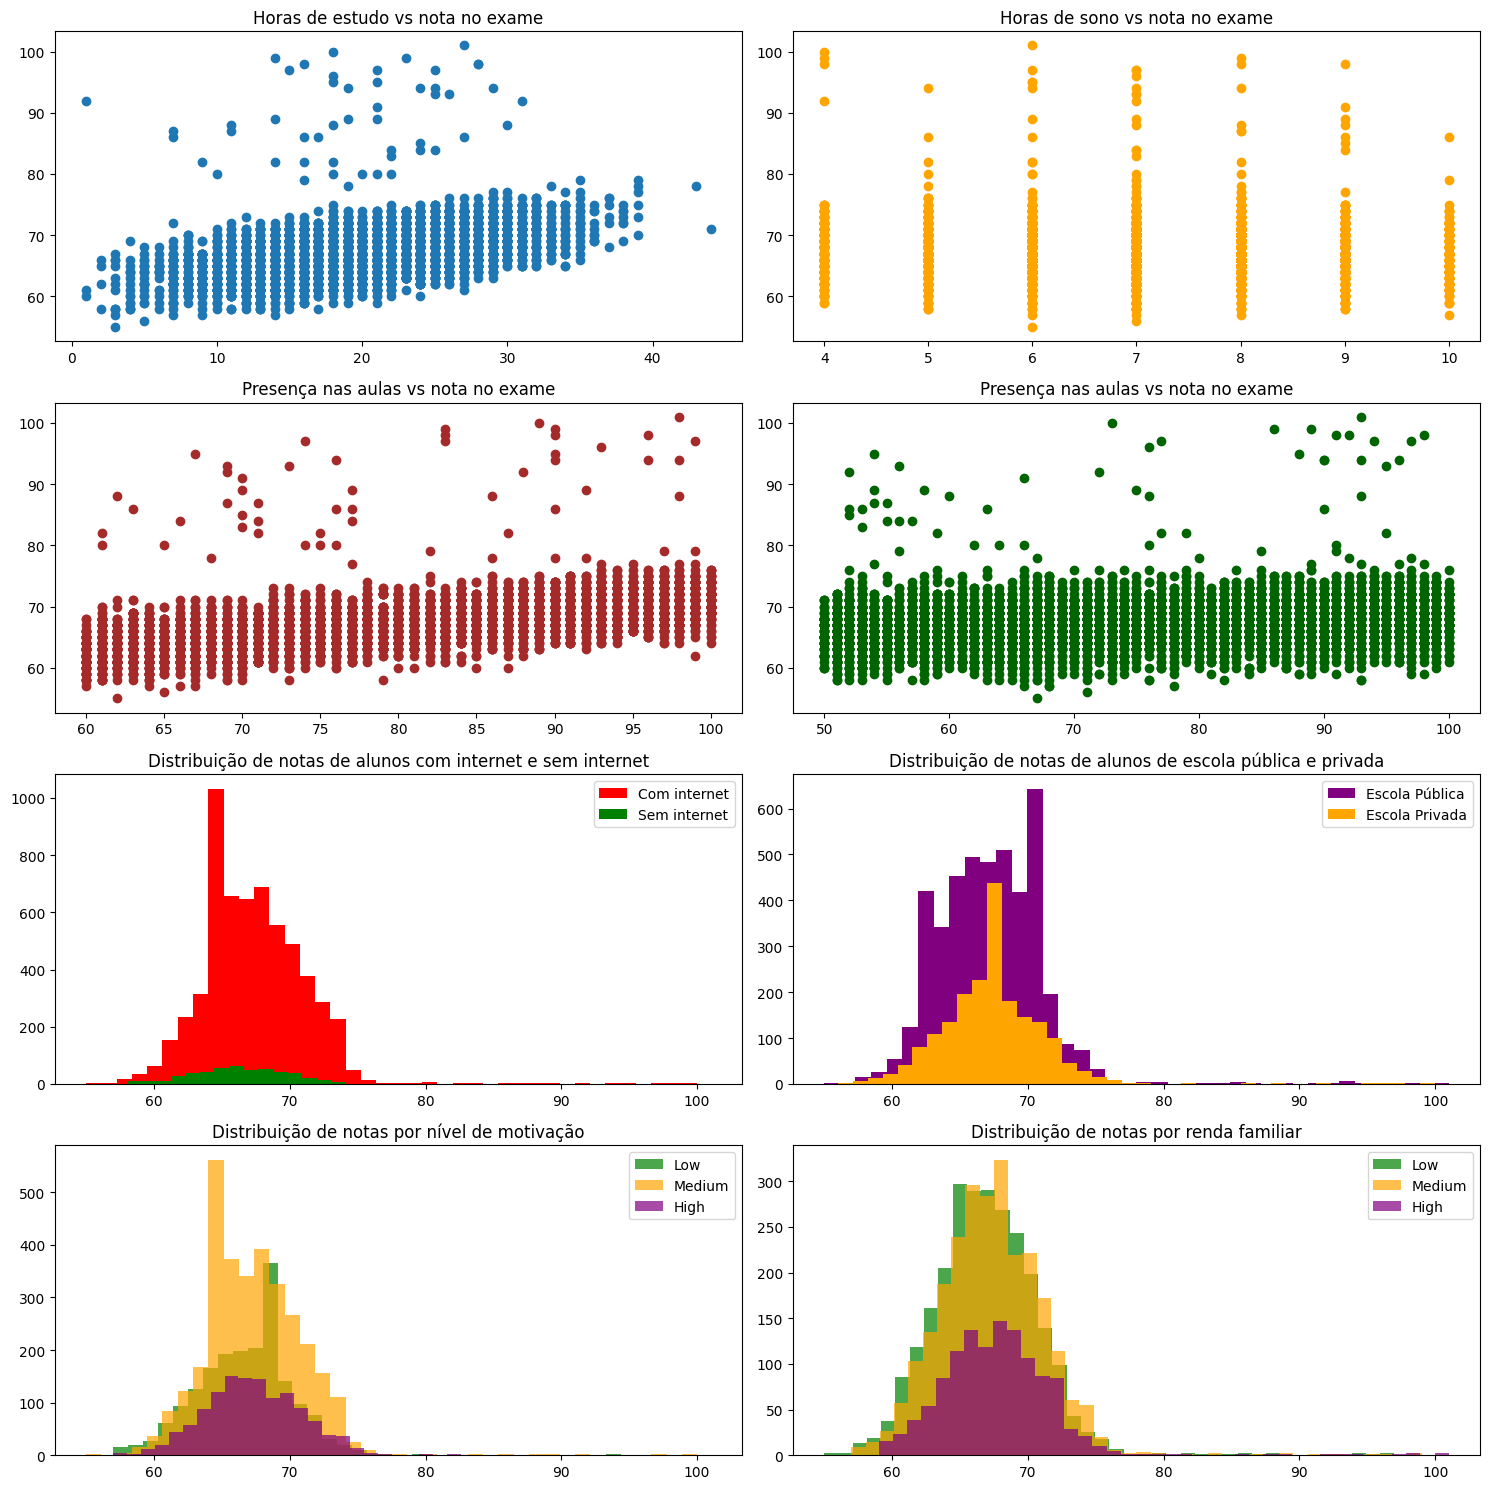

In [ ]:
fig, ax = plt.subplots(4, 2, figsize=(15, 15))

# 1. Horas de estudo vs nota
ax[0, 0].scatter(student_performance_df['Hours_Studied'], student_performance_df['Exam_Score'])
ax[0, 0].set_title('Horas de estudo vs nota no exame')

# 2. Horas de sono vs nota
ax[0, 1].scatter(student_performance_df['Sleep_Hours'], student_performance_df['Exam_Score'], color='orange')
ax[0, 1].set_title('Horas de sono vs nota no exame')

# 3. Presença nas aulas
ax[1, 0].scatter(student_performance_df['Attendance'], student_performance_df['Exam_Score'], color = 'brown')
ax[1, 0].set_title('Presença nas aulas vs nota no exame')

# 4. Notas anteriores
ax[1, 1].scatter(student_performance_df['Previous_Scores'], student_performance_df['Exam_Score'], color = 'darkgreen')
ax[1, 1].set_title('Presença nas aulas vs nota no exame')

# 5. Internet
com_internet = student_performance_df['Internet_Access'] == 'Yes'
ax[2, 0].hist(student_performance_df[com_internet]['Exam_Score'], color='red', bins=40, label='Com internet')
ax[2, 0].hist(student_performance_df[~com_internet]['Exam_Score'], color='green', bins=40, label='Sem internet')
ax[2, 0].legend(loc='upper right')
ax[2, 0].set_title('Distribuição de notas de alunos com internet e sem internet')

# 6. Tipo de escola
escola_publica = student_performance_df['School_Type'] == 'Public'
ax[2, 1].hist(student_performance_df[escola_publica]['Exam_Score'], color='purple', bins=40, label='Escola Pública')
ax[2, 1].hist(student_performance_df[~escola_publica]['Exam_Score'], color='orange', bins=40, label='Escola Privada')
ax[2, 1].legend(loc='upper right')
ax[2, 1].set_title('Distribuição de notas de alunos de escola pública e privada')

# 7. Motivação
for level, color in zip(['Low', 'Medium', 'High'], ['green', 'orange', 'purple']):
    filtro = student_performance_df['Motivation_Level'] == level
    ax[3, 0].hist(student_performance_df[filtro]['Exam_Score'], color=color, bins=40, label=level, alpha=0.7)
ax[3, 0].legend(loc='upper right')
ax[3, 0].set_title('Distribuição de notas por nível de motivação')

# 8. Renda familiar
for level, color in zip(['Low', 'Medium', 'High'], ['green', 'orange', 'purple']):
    filtro = student_performance_df['Family_Income'] == level
    ax[3, 1].hist(student_performance_df[filtro]['Exam_Score'], color=color, bins=40, label=level, alpha=0.7)
ax[3, 1].legend(loc='upper right')
ax[3, 1].set_title('Distribuição de notas por renda familiar')


plt.tight_layout()  # evita sobreposição
plt.show()

- Parece haver forte correlação linear entre as variáveis explicativas número de horas de estudo, presença nas aulas e horas dormidas com a variável respospta pontuação no exame.
- O gráfico de número de horas dormidas vs nota no exame é inconclusivo.
- Olhando as distribuições de notas por categorias de escolas, acesso a internet, renda familiar e nível de motivação, aparentemente esses são fatores que não possuem impacto nas notas dos alunos.

Outro gráfico interessante seria um Radar Plot para analisar o perfil dos alunos das 10% melhores notas e das 10% piores notas.

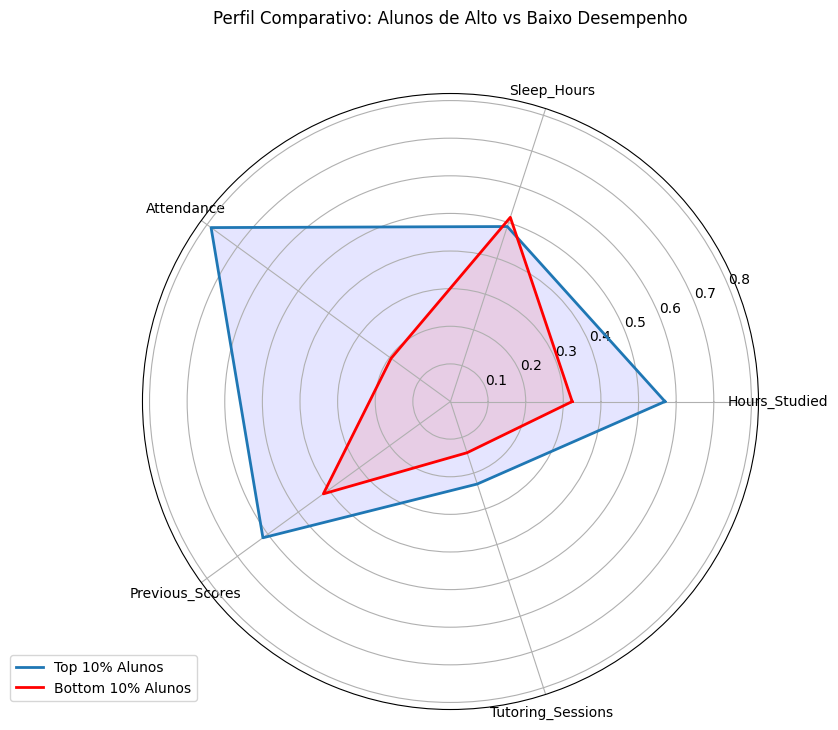

In [ ]:
# --- Visualização Alternativa: Gráfico de Radar (Perfil dos Alunos) ---
# Vamos normalizar os dados originais (numéricos) para escala 0-1 para visualização
df_viz = student_performance_df.select_dtypes(include=[np.number]).copy()
df_viz = (df_viz - df_viz.min()) / (df_viz.max() - df_viz.min())

# Definir grupos: Top 10% notas vs Bottom 10% notas
limit_high = df_viz['Exam_Score'].quantile(0.9)
limit_low = df_viz['Exam_Score'].quantile(0.1)

high_performers = df_viz[df_viz['Exam_Score'] >= limit_high].mean()
low_performers = df_viz[df_viz['Exam_Score'] <= limit_low].mean()

# Selecionar algumas variáveis para o radar (excluindo a própria nota)
variables = ['Hours_Studied', 'Sleep_Hours', 'Attendance', 'Previous_Scores', 'Tutoring_Sessions']
# Certifique-se que essas colunas existem no seu df original, ajuste se necessário

# Dados para o plot
values_high = high_performers[variables].values.tolist()
values_low = low_performers[variables].values.tolist()
values_high += values_high[:1] # Fechar o ciclo
values_low += values_low[:1]   # Fechar o ciclo

angles = [n / float(len(variables)) * 2 * pi for n in range(len(variables))]
angles += angles[:1]

# Plot
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Draw one axe per variable + add labels
plt.xticks(angles[:-1], variables)

# Plot High Performers
ax.plot(angles, values_high, linewidth=2, linestyle='solid', label='Top 10% Alunos')
ax.fill(angles, values_high, 'b', alpha=0.1)

# Plot Low Performers
ax.plot(angles, values_low, linewidth=2, linestyle='solid', label='Bottom 10% Alunos', color='red')
ax.fill(angles, values_low, 'r', alpha=0.1)

plt.title('Perfil Comparativo: Alunos de Alto vs Baixo Desempenho', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.show()

# Pergunta 1:
### É possível utilizar os fatores socioeconômicos e individuais para prever a nota com alta precisão?

Para responder a esta pergunta, adotamos uma abordagem comparativa utilizando dois paradigmas distintos de Machine Learning:

    Regressão Linear Regularizada (Lasso): Focada em capturar relações lineares e realizar seleção de variáveis (feature selection).

        Robustez: Utilizamos LassoCV para encontrar o hiperparâmetro de penalização (alpha) ideal via validação cruzada.

        Diagnóstico: Validamos os pressupostos clássicos (Normalidade, Homocedasticidade e Significância Global).

    Random Forest Regressor: Focado em capturar não-linearidades complexas.

        Engenharia de Modelo: Implementamos um Grid Search Manual paralelizado via biblioteca multiprocessing (para otimizar o uso da CPU) e avaliamos via Validação Cruzada (K-Fold).

        Confiabilidade: Calculamos o Intervalo de Confiança do erro via método Bootstrap.

Abaixo, apresentamos os resultados e a comparação direta entre as abordagens.

### Regressão Linear com Lasso

In [ ]:

# LassoCV testa vários alphas automaticamente usando k-fold (cv=5 padrão), para selecionar as variáveis mais úteis
lasso_model = LassoCV(cv=5, random_state=42, max_iter=10000, n_jobs=-1)
lasso_model.fit(Z_train, y_train)

print(f"Alpha encontrado: {lasso_model.alpha_:.6f}")

# Previsões
y_pred_lasso = lasso_model.predict(Z_test)


Alpha encontrado: 0.002235


In [ ]:
# Utilizaremos as métricas RMSE, MAE e R^2 para avaliar a regressão

rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("\n Performance do Modelo Lasso")
print(f"RMSE: {rmse_lasso:.4f}")
print(f"MAE:  {mae_lasso:.4f}")
print(f"R²:   {r2_lasso:.4f}")



 Performance do Modelo Lasso
RMSE: 2.0150
MAE:  0.4850
R²:   0.7346


In [ ]:
# Construção de um IC para o RMSE a partir de bootstrap

n_bootstraps = 1000
bootstrapped_rmses = []
rng = np.random.RandomState(42)
y_test_np = y_test.values
y_pred_np = y_pred_lasso

for i in range(n_bootstraps):
    indices = rng.randint(0, len(y_pred_np), len(y_pred_np))
    if len(np.unique(y_test_np[indices])) < 2: continue
    score = np.sqrt(mean_squared_error(y_test_np[indices], y_pred_np[indices]))
    bootstrapped_rmses.append(score)

ci_lower = np.percentile(bootstrapped_rmses, 2.5)
ci_upper = np.percentile(bootstrapped_rmses, 97.5)
print(f"IC 95% para RMSE: [{ci_lower:.4f}, {ci_upper:.4f}]")

IC 95% para RMSE: [1.4517, 2.5293]


In [ ]:

# Ver quantas variáveis a LASSO selecionou
coefs = pd.Series(lasso_model.coef_, index=Z_train.columns)
selected_vars = coefs[coefs != 0].index.tolist()
print(f"\nVariáveis selecionadas pelo Lasso: {len(selected_vars)} de {Z_train.shape[1]}")


Variáveis selecionadas pelo Lasso: 27 de 27


A Lasso selecionou todas as variáveis provavelmente por causa do tamanho da amostra, que acaba inflando a significância das variáveis.

In [ ]:

X_subset = Z_train[selected_vars].astype(float)
y_train_numeric = y_train.astype(float)

# Adiciona constante para o intercepto
X_ols = sm.add_constant(X_subset)

# Ajusta o modelo OLS para estatísticas
ols_model = sm.OLS(y_train_numeric, X_ols).fit()

print("\nValidação do modelo MQO")
print(f"Estatística F: {ols_model.fvalue:.2f} (p-valor: {ols_model.f_pvalue:.4e})")



# Diagnóstico dos Resíduos
# Garantir que y_test e y_pred também sejam comparáveis
y_test_numeric = y_test.astype(float)
residuos = y_test_numeric - y_pred_lasso

# A) Teste de Normalidade (Shapiro-Wilk)
stat_shapiro, p_shapiro = stats.shapiro(residuos)
print(f"\nTeste de Shapiro-Wilk (Normalidade dos resíduos):")
print(f"Estatística: {stat_shapiro:.4f}, p-valor: {p_shapiro:.4e}")

# B) Teste de Homocedasticidade (Breusch-Pagan)
# Precisamos das variáveis exógenas correspondentes ao teste (adicionando constante)
# Nota: Usamos as variáveis do teste (Z_test) para verificar nos resíduos de teste
X_test_ols = sm.add_constant(Z_test[selected_vars].astype(float))

bp_test = het_breuschpagan(residuos, X_test_ols)
p_bp = bp_test[1]
print(f"Teste de Breusch-Pagan (Homocedasticidade):")
print(f"p-valor: {p_bp:.4e}")



Validação do modelo MQO
Estatística F: 413.23 (p-valor: 0.0000e+00)

Teste de Shapiro-Wilk (Normalidade dos resíduos):
Estatística: 0.1605, p-valor: 2.4081e-68
Teste de Breusch-Pagan (Homocedasticidade):
p-valor: 6.5125e-01


O modelo é válido. A estatística F teve um valor extremamente alto, o que indica que nosso modelo é estatisticamente significante e melhor que o modelo mais simples. O teste de Shapiro-Wilk diz que nossa suposição de que os erros vem de uma Normal(0,1) é inválida, porém, como nossa amostra é grande, o TCL garante que nossos resultados de coeficientes são válidos. Por fim, o Teste de Breusch-Pagan confirma a hipótese de Homocedasticidade, já que seu p-valor é alto (0.65)

O modelo Lasso apresentou uma performance boa, indicando uma forte linearidade nos dados.

    R² (0.7346): O modelo consegue explicar cerca de 73,5% da variação das notas dos alunos. Este é um valor considerado alto para dados comportamentais.

    MAE (0.4850): O erro médio absoluto é inferior a 0.5 pontos, indicando altíssima precisão nas previsões pontuais.

    Seleção de Variáveis: O Lasso manteve 27 de 27 variáveis. O alpha ótimo encontrado foi muito baixo (0.0022), o que significa que o modelo convergiu para uma solução muito próxima da Regressão Linear padrão, utilizando todas as informações disponíveis sem descartar preditores.

### Random Forest

In [ ]:
# Função que será executada em paralelo
# Recebe uma tupla (parametros, X_train, y_train)
def avaliar_hiperparametros(args):
    params, X, y = args
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_scores = []

    # Loop de Validação Cruzada (K-Fold) manual
    for train_idx, val_idx in kf.split(X):
        # Separação dos dados baseada nos índices do fold
        X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
        y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

        # Treino do modelo com os parâmetros atuais
        # n_jobs=1 garante que cada processo use apenas 1 núcleo, já que vamos paralelizar o Grid Search
        model = RandomForestRegressor(**params, random_state=42, n_jobs=1)
        model.fit(X_train_fold, y_train_fold)

        # Avaliação
        preds = model.predict(X_val_fold)
        rmse = np.sqrt(mean_squared_error(y_val_fold, preds))
        rmse_scores.append(rmse)

    # Retorna a média do RMSE nesses folds
    return params, np.mean(rmse_scores)

In [ ]:
# Definição do Grid de Hiperparâmetros
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

# Criação de todas as combinações possíveis (Produto Cartesiano)
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

print(f"Total de combinações de hiperparâmetros a testar: {len(param_combinations)}")

# Execução do Grid Search com Multiprocessing
if __name__ == '__main__':
    # Prepara os argumentos para passar para a função (params, X, y)
    # Nota: Copiar dados para processos pode ser custoso em RAM, mas eficiente para datasets médios
    args_list = [(params, Z_train, y_train) for params in param_combinations]

    # Cria um Pool de processos (usa todos os núcleos disponíveis)
    with multiprocessing.Pool(processes=multiprocessing.cpu_count()) as pool:
        results = pool.map(avaliar_hiperparametros, args_list)

    # Seleção do Melhor Modelo
    # Ordena os resultados pelo menor RMSE médio
    results.sort(key=lambda x: x[1])
    best_params, best_score = results[0]

    print(f"\nMelhores parâmetros encontrados: {best_params}")
    print(f"Melhor RMSE médio na Validação Cruzada: {best_score:.4f}")

    #  Treino do Modelo Final e Avaliação no Teste
    final_model = RandomForestRegressor(**best_params, random_state=42)
    final_model.fit(Z_train, y_train)
    y_pred = final_model.predict(Z_test)

    # Métricas Finais
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
    mae_test = mean_absolute_error(y_test, y_pred)
    r2_test = r2_score(y_test, y_pred)

    print("\n--- Resultados no Conjunto de Teste ---")
    print(f"RMSE: {rmse_test:.4f}")
    print(f"MAE: {mae_test:.4f}")
    print(f"R²: {r2_test:.4f}")

    # Cálculo do Intervalo de Confiança (Bootstrap)
    # Critério: "Fez ICS para o valor de corretude"
    n_bootstraps = 1000
    bootstrapped_rmses = []
    rng = np.random.RandomState(42)

    y_test_np = y_test.values
    y_pred_np = y_pred

    for i in range(n_bootstraps):
        # Amostragem com reposição
        indices = rng.randint(0, len(y_pred_np), len(y_pred_np))
        if len(np.unique(y_test_np[indices])) < 2:
            continue
        score = np.sqrt(mean_squared_error(y_test_np[indices], y_pred_np[indices]))
        bootstrapped_rmses.append(score)

    sorted_scores = np.array(bootstrapped_rmses)
    ci_lower = np.percentile(sorted_scores, 2.5)
    ci_upper = np.percentile(sorted_scores, 97.5)

    print(f"\nIntervalo de Confiança (95%) para o RMSE: [{ci_lower:.4f}, {ci_upper:.4f}]")

Total de combinações de hiperparâmetros a testar: 27

Melhores parâmetros encontrados: {'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 10}
Melhor RMSE médio na Validação Cruzada: 2.4991

--- Resultados no Conjunto de Teste ---
RMSE: 2.3804
MAE: 1.2267
R²: 0.6296

Intervalo de Confiança (95%) para o RMSE: [1.9436, 2.8430]


Após a otimização de hiperparâmetros (n_estimators: 200, max_depth: 20, min_samples_split: 10) via Grid Search Paralelo:

    R² (0.6296): Explicou cerca de 63% da variância.

    RMSE (2.3804): O erro quadrático médio foi significativamente maior que o do Lasso (que foi 2.01).

    Intervalo de Confiança (RMSE): [1.94, 2.84]. Note que mesmo o melhor cenário do Random Forest (1.94) é apenas marginalmente melhor que a média do Lasso, mostrando a inferioridade deste modelo para este problema específico.

### CONCLUSÃO

Após a implementação e otimização de ambos os modelos, observamos um fenômeno interessante:

1.  **Regressão Linear (Lasso):** Apresentou o melhor desempenho (menor erro).
2.  **Random Forest:** Mesmo após o Grid Search, obteve um desempenho ligeiramente inferior.

### Interpretação do Fenômeno
Este resultado sugere que a relação entre as variáveis explicativas (horas de estudo, frequência, etc.) e a variável alvo (Nota) é **predominantemente linear**.

O Random Forest é um modelo não-linear que tenta aproximar a função real através de segmentações no espaço (árvores de decisão). Quando a relação verdadeira é uma linha reta simples, a Regressão Linear consegue capturá-la de forma exata, enquanto o Random Forest cria uma aproximação "em degraus", perdendo precisão nas bordas.

**Conclusão do Projeto:**
Ambos os modelos atingiram um resultado aceitável na predição da nota de um aluno a partir dos dados apresentados. Portanto, é possível dizer que fatores socioeconômicos, culturais e individuais são bons preditores da nota final de um estudante.


# Pergunta 2:
### Quais os fatores que mais impactam a nota de um aluno?

Uma das grandes vantagens do Random Forest sobre modelos "caixa-preta" é a capacidade de medir a **Feature Importance** (Importância das Variáveis).

Ao contrário dos coeficientes da Regressão Linear (que mostram direção positiva/negativa), o gráfico abaixo mostra a **magnitude do impacto**. Ele representa o quanto cada variável contribuiu para reduzir a impureza (erro) nas árvores de decisão durante o treinamento.

Variáveis no topo são as melhores preditoras do desempenho do aluno.

### Visualizando importância (impacto) das variáveis:

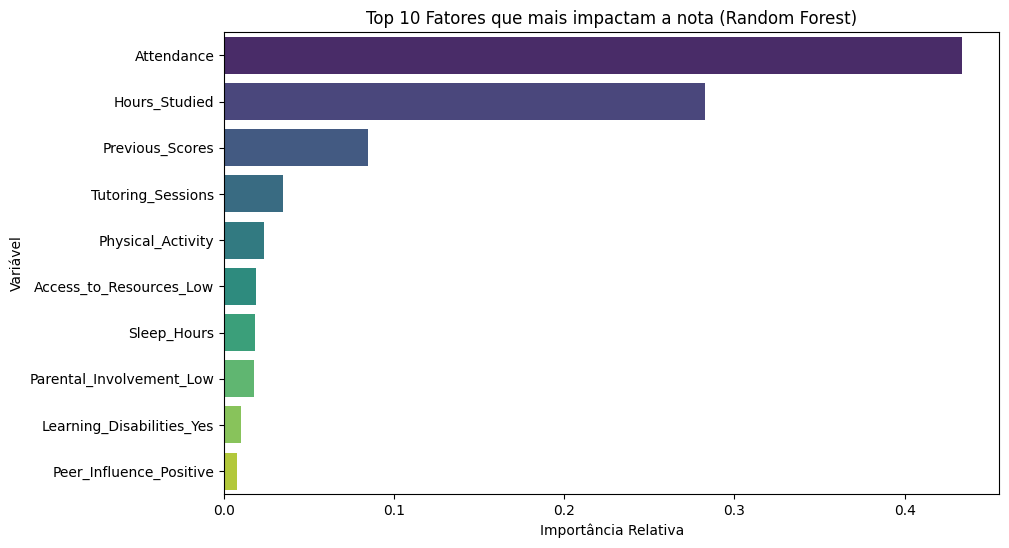

In [ ]:
# Extração da Importância das Variáveis (Feature Importance)
importances = final_model.feature_importances_
feature_names = Z_train.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Ordenar e pegar as Top 10
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis', hue='Feature')
plt.title('Top 10 Fatores que mais impactam a nota (Random Forest)')
plt.xlabel('Importância Relativa')
plt.ylabel('Variável')
plt.show()



Aparentemente, fatores comportamentais como frequência e horas de estudo do aluno são, com uma grande margem, os dois fatores mais importantes para predizer sua nota.

# Pergunta 3:
### A partir de quantos % de presença o aluno fica acima da média?
***Considerando nota acima da média = nota > 60.**  
Para responder a esta pergunta, adotamos uma abordagem comparativa, utilizando o modelo de regressão logística sem e com CV e um outro algoritmo de seleção de modelos: XGBoost.

    Regressão Logística: Focada em usar variáveis de quaisquer tipos (categóricas ou numéricas) para predizer uma variável y de sucesso ou fracasso (0 e 1).

        Robustez: Utilizamos LogisitcRegressionCV para encontrar o hiperparâmetro de penalização (C = 1/lambda) ideal via validação cruzada.

    XGBoost: Algoritmo de aprendizado de máquina focado em classificação e regressão.

Abaixo, apresentamos os resultados e a comparação direta entre as abordagens.

In [ ]:
nota_media = 60

# Splittando dados
X_train, X_test, y_train, y_test = train_test_split(
    Z, Y, test_size=0.3, random_state=42
)

# Tratando booleanos
for df in [X_train, X_test]:
    bool_cols = df.select_dtypes(include=['bool']).columns
    df[bool_cols] = df[bool_cols].astype(int)

# Padronizando
X_train_num = scaler.fit_transform(X_train[numerical_cols])
X_test_num = scaler.fit_transform(X_test[numerical_cols])

# Criando dummies
X_train_cat = pd.get_dummies(X_train[categorical_cols], drop_first=True)
X_test_cat = pd.get_dummies(X_test[categorical_cols], drop_first=True)
# Para o caso de alguma coluna ser perdida no conjunto menor
X_test_cat = X_test_cat.reindex(columns=X_train_cat.columns, fill_value=0)

# Monta X_train e X_test
X_train = pd.concat([pd.DataFrame(X_train_num, index=X_train.index, columns=numerical_cols), X_train_cat], axis=1)
X_test = pd.concat([pd.DataFrame(X_test_num, index=X_test.index, columns=numerical_cols), X_test_cat], axis=1)

# Garante feature names do tipo string
X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

# Cria y_log (y para reg logistica)
y_train_log = (y_train > nota_media).astype(int)
y_test_log = (y_test > nota_media).astype(int)


## Regressão Logística

In [ ]:
from sklearn.linear_model import LogisticRegression

# Rodando a regressao com:
# loss = log, logistic
# penalizando com norma L2
# otimizando com Limited-memory BFGS
model = LogisticRegression(penalty='l2', fit_intercept=True, solver='lbfgs')
model.fit(X_train, y_train_log)

LogisticRegression()

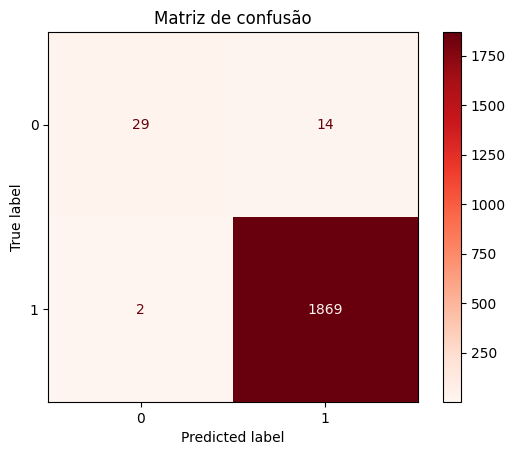

Proporção de Y=1 no conjunto de treino:
0.9780465949820788

F1 Score:  0.9957378795950985
ROC-AUC Score:  0.9984462978384896
Brier-Score loss:  0.005880406064622412


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss, classification_report

# Tira métricas
y_scores = model.predict_proba(X_test)[:,1]
y_true = y_test_log.copy()
y_pred = model.predict(X_test)
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap='Reds')
plt.title('Matriz de confusão')
plt.show()

print('Proporção de Y=1 no conjunto de treino:')
print(y_train_log.mean())
print("\nF1 Score: ", f1_score(y_true, y_pred))
print("ROC-AUC Score: ", roc_auc_score(y_true, y_scores))
print("Brier-Score loss: ", brier_score_loss(y_true, y_scores))

- Os dados parecem estar desbalanceados pela proporção de alunos acima da média, mas as scores apontam o contrário: o modelo parece estar indo muito bem. Vamos verificar:

In [ ]:
print("Proporção de Y=1 no train:", y_train_log.mean())
print("Proporção de Y=1 no test :", y_test_log.mean())

Proporção de Y=1 no train: 0.9780465949820788
Proporção de Y=1 no test : 0.977533960292581


- Também parecem desbalanceados, mas mantiveram a proporção do original.


## Reg. Logística com CV

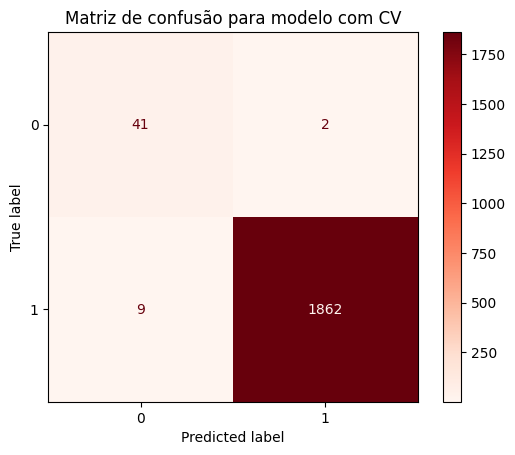


F1 Score:  0.9970548862115127
ROC-AUC Score:  0.9992293637278908
Brier-Score loss:  0.004139273701272813


In [ ]:
from sklearn.linear_model import LogisticRegressionCV

# Rodando o modelo com uma validação cruzada KFold automática
# Internamente, um C = (1/lambda) (parametro de penalização) eh encontrado para regularizar coeficientes do modelo
model_cv = LogisticRegressionCV(cv=10,                  # K=10 para estabilidade
                                fit_intercept=True,
                                penalty='l2',           # Mesma penalização
                                solver='lbfgs',         # Mesma otimização
                                scoring='roc_auc',      # Métrica usada para avaliar C
                                max_iter=500,           # Mais iterações
                                class_weight='balanced' # Penaliza classes mais frequentes, ja que dados estão desbalanceados
                                )
model_cv.fit(X_train, y_train_log)

# Tira métricas
y_true = y_test_log.copy()
y_pred = model_cv.predict(X_test)
y_scores = model_cv.predict_proba(X_test)[:,1]
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap='Reds')
plt.title('Matriz de confusão para modelo com CV')
plt.show()

print("\nF1 Score: ", f1_score(y_true, y_pred))
print("ROC-AUC Score: ", roc_auc_score(y_true, y_scores))
print("Brier-Score loss: ", brier_score_loss(y_true, y_scores))

- Pequenos aumentos, mas já bem próximos do teto. Tentando com XGBoost e seu ajuste de hiperparâmetros com árvores de decisão:

## Treinando com XGBoost

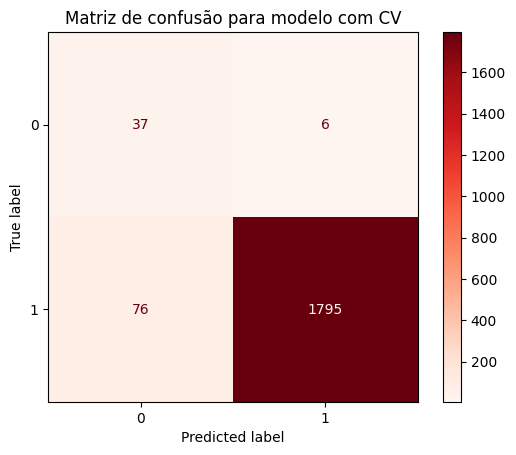


F1 Score:  0.9776688453159041
ROC-AUC Score:  0.9892359514250556
Brier-Score loss:  0.028854218525671955


In [ ]:
import xgboost as xgb

# Peso relativo das classes
scale = (1 - y_train_log.mean()) / y_train_log.mean()

# Modelo
model_xgb = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',             # métrica interna
    scale_pos_weight=scale,        # ajuste para o desbalanceamento
    n_estimators=300,              # número de árvores
    max_depth=5,                   # maior numero de niveis da árvore
    subsample=0.8,                 # fração de amostras por árvore
    colsample_bytree=0.8,          # fração de features por árvore
    learning_rate=0.05,
    random_state=42
)

model_xgb.fit(X_train, y_train_log)

y_true = y_test_log.copy()
y_pred = model_xgb.predict(X_test)
y_scores = model_xgb.predict_proba(X_test)[:,1]
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap='Reds')
plt.title('Matriz de confusão para modelo com CV')
plt.show()

print("\nF1 Score: ", f1_score(y_true, y_pred))
print("ROC-AUC Score: ", roc_auc_score(y_true, y_scores))
print("Brier-Score loss: ", brier_score_loss(y_true, y_scores))

- Falsos negativos aumentaram, mas falsos positivos diminuíram. Avaliando as pontuações, o modelo parece ter ido um pouquinho pior, mas ainda está muito bom.  

Neste caso aqui, ficaremos com a regressão logística obtida com CV, pois não é desejado um falso negativo para predizer a nota de um aluno - ele seria reprovado tendo tido nota suficiente, na verdade.  
Como os dados estão padronizados, podemos obter o impacto de cada variável pelo valor absoluto de seu coeficiente na regressão com penalização que usamos:

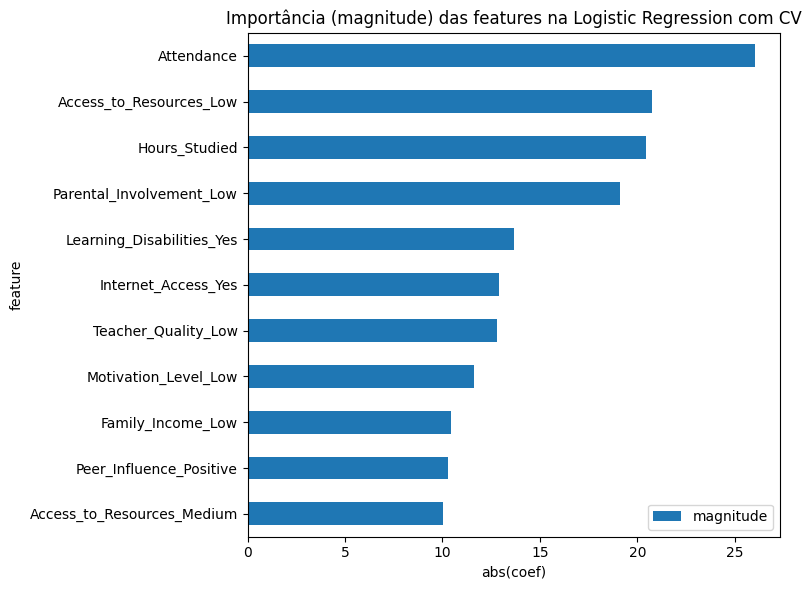

In [ ]:
# Coeficientes do modelo (é uma matriz de shape (1, n_features) em binário)
coefs = model_cv.coef_.ravel()

importancia = pd.DataFrame({
    'feature': X_train.columns,
    'coeficiente': coefs,
    'magnitude': np.abs(coefs)
})

# Plotando as 11 maiores importancias ordenadas
importancia = importancia.sort_values('magnitude', ascending=False)
top_n = 11
importancia.head(top_n).plot(
    x='feature',
    y='magnitude',
    kind='barh',
    figsize=(8,6),
)
plt.gca().invert_yaxis()
plt.title('Importância (magnitude) das features na Logistic Regression com CV')
plt.xlabel('abs(coef)')
plt.tight_layout()
plt.show()

In [ ]:
student_performance_df[student_performance_df['Exam_Score'] < 60]

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
283,13,69,Medium,Low,Yes,5,68,Low,Yes,0,High,Medium,Public,Positive,1,Yes,High School,Moderate,Female,59
504,16,60,Low,Medium,Yes,8,66,Low,Yes,1,High,High,Private,Neutral,2,Yes,High School,Moderate,Female,59
524,15,63,Medium,Low,No,8,55,Low,Yes,0,Medium,Low,Public,Neutral,3,No,College,Near,Female,59
646,4,64,Medium,High,Yes,7,65,Medium,Yes,1,Medium,High,Public,Negative,4,No,High School,Far,Male,59
668,4,69,Medium,Low,No,9,93,Low,No,2,Medium,High,Private,Negative,3,No,High School,Moderate,Female,58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6092,19,61,High,Medium,Yes,6,52,Low,No,1,Low,Medium,Public,Neutral,3,No,High School,Far,Female,59
6102,13,69,Medium,Low,Yes,7,53,High,No,2,Medium,Medium,Private,Negative,3,Yes,High School,Near,Female,59
6125,15,67,Low,Medium,Yes,5,59,Low,Yes,0,Low,Medium,Private,Neutral,3,No,High School,Near,Male,59
6431,4,60,Medium,Medium,Yes,7,55,Medium,Yes,2,Low,Medium,Private,Neutral,2,No,Postgraduate,Near,Male,58


A feature "presença" é a mais importante aqui também. Curiosamente, o acesso aos recursos também mostrou muita importância, diferentemente da LASSO feita previamente. É exatamente elas que usaremos para responder à pergunta.

## Predição

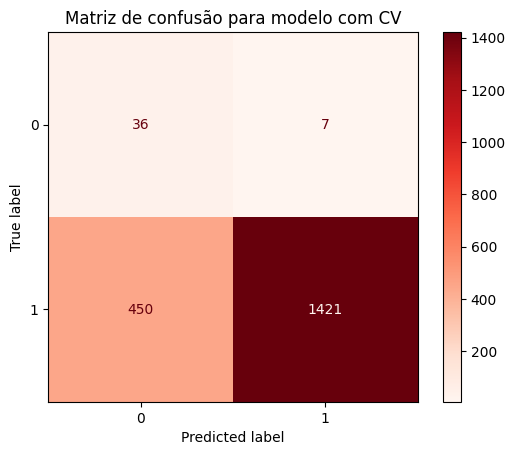


F1 Score:  0.8614731736889967
ROC-AUC Score:  0.8741252656830696
Brier-Score loss:  0.14508743413825617
Presença necessária para que fique acima da média um aluno com nível de acesso a recrusos:
Alto   : 67.67 %
Médio  : 70.32 %
Baixo  : 72.42 %


In [ ]:
# Mesmo ajuste do que teve melhores reseultados na base
model_pred = LogisticRegressionCV(cv=10,
                                fit_intercept=True,
                                penalty='l2',
                                solver='lbfgs',
                                scoring='roc_auc',
                                max_iter=500,
                                class_weight='balanced'
                                )
# Rodando o modelo apenas com presenca e acesso aos recursos, variaveis que usaremos
X_train_pred = X_train[['Attendance', 'Access_to_Resources_Low', 'Access_to_Resources_Medium']].copy()
X_test_pred = X_test[['Attendance', 'Access_to_Resources_Low', 'Access_to_Resources_Medium']].copy()
model_pred.fit(X_train_pred, y_train_log)

# Tira métricas
y_true = y_test_log.copy()
y_pred = model_pred.predict(X_test_pred)
y_scores = model_pred.predict_proba(X_test_pred)[:,1]
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap='Reds')
plt.title('Matriz de confusão para modelo com CV')
plt.show()

print("\nF1 Score: ", f1_score(y_true, y_pred))
print("ROC-AUC Score: ", roc_auc_score(y_true, y_scores))
print("Brier-Score loss: ", brier_score_loss(y_true, y_scores))

# Predizendo os 3 valores (um para cada categoria de "Access_to_Resources")
# Usando o threshold usual p = 0.5, para o qual z deve ser 0 na função logit
# z = b0 + b1*presenca + b2*low + b3*medium (high eh grupo base)
# isolando presenca, com z = 0: presenca = -b0/b*categoria
b0 = model_pred.intercept_[0]
b_pres = model_pred.coef_[0][X_train_pred.columns.get_loc('Attendance')]
b_low  = model_pred.coef_[0][X_train_pred.columns.get_loc('Access_to_Resources_Low')]
b_med  = model_pred.coef_[0][X_train_pred.columns.get_loc('Access_to_Resources_Medium')]
# Limiares por categoria
cut_high   = -(b0 + 0)     / b_pres
cut_medium = -(b0 + b_med) / b_pres
cut_low    = -(b0 + b_low) / b_pres
# Retirando padronização de seus valores
std_att = scaler.scale_[1] # "attendance" era a segunda coluna da lista numerical_cols usada na padronização
mean_att = scaler.mean_[1]
cut_high = cut_high * std_att + mean_att
cut_medium = cut_medium * std_att + mean_att
cut_low = cut_low * std_att + mean_att

print("Presença necessária para que fique acima da média um aluno com nível de acesso a recrusos:")
print("Alto   :", np.round(cut_high, 2), "%")
print("Médio  :", np.round(cut_medium, 2), "%")
print("Baixo  :", np.round(cut_low, 2), "%")

## CONCLUSÃO:

A matriz de confusão revela muito mais falsos positivos, o que era de se esperar, pois aparentemente todas as features trabalham juntas para construir um modelo melhor, e aqui ele foi treinado com 3 features apenas. No entanto, pelos valores ainda que aceitáveis das scores, também aceitamos as predições feitas.

# Pergunta 4:
### Existe um número de horas de estudo a partir do qual a nota para de aumentar significativamente?

### Reg Plot:

       Hours_Studied   Exam_Score
count    6378.000000  6378.000000
mean       19.977109    67.252117
std         5.985460     3.914217
min         1.000000    55.000000
25%        16.000000    65.000000
50%        20.000000    67.000000
75%        24.000000    69.000000
max        44.000000   101.000000


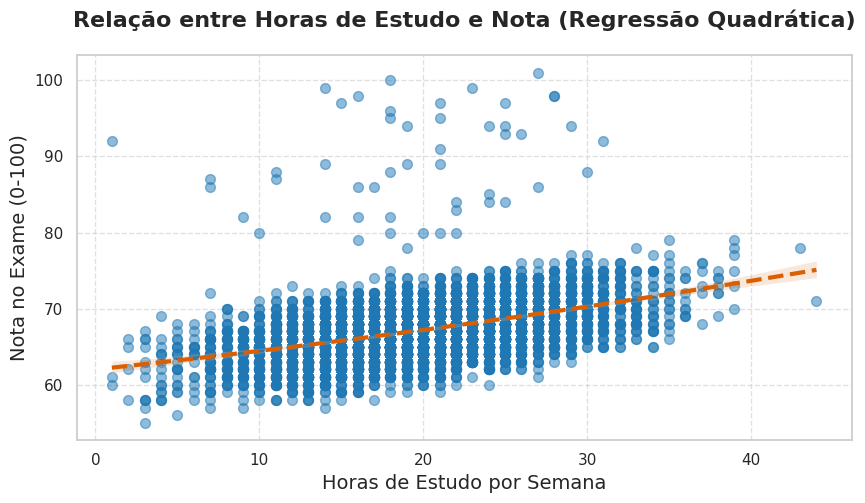

In [ ]:
sns.set_theme(style="whitegrid")

print(student_performance_df[['Hours_Studied', 'Exam_Score']].describe())

# Plot 1: Gráfico de Regressão Quadrática
# Este gráfico nos permite ver visualmente se a linha de tendência se achata

plt.figure(figsize=(10, 5))
sns.regplot(
    data=student_performance_df,
    x='Hours_Studied',
    y='Exam_Score',
    order=2,
    line_kws={'color': '#d95f02', 'linewidth': 3, 'linestyle': '--'},
    scatter_kws={'alpha': 0.5, 's': 50, 'color': '#1f78b4'}
)
plt.title('Relação entre Horas de Estudo e Nota (Regressão Quadrática)', fontsize=16, weight='bold', pad=20)
plt.xlabel('Horas de Estudo por Semana', fontsize=14)
plt.ylabel('Nota no Exame (0-100)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Obtendo ICs

In [ ]:
print("Número de alunos que tiveram:")
for h in np.arange(10):
  print(f"{h} hora(s) de estudo por semana: ")
  print(student_performance_df[student_performance_df["Hours_Studied"] == h].shape[0])

Número de alunos que tiveram:
0 hora(s) de estudo por semana: 
0
1 hora(s) de estudo por semana: 
3
2 hora(s) de estudo por semana: 
4
3 hora(s) de estudo por semana: 
12
4 hora(s) de estudo por semana: 
16
5 hora(s) de estudo por semana: 
21
6 hora(s) de estudo por semana: 
17
7 hora(s) de estudo por semana: 
51
8 hora(s) de estudo por semana: 
55
9 hora(s) de estudo por semana: 
79


A partir de 5 horas de estudo por semana o numero de observações já é interessante e não deve fazer um intervalo de confiança muito grande ($\sigma/\sqrt{n}$ pequeno).

In [ ]:
from multiprocessing import Pool, cpu_count # Para otimizar calculos

# Funcao para Calcular o IC (mantendo a funcao do exemplo anterior)
def calcular_ic_para_bin(notas_bin, confianca=0.95):
    """Calcula a média e o IC para as notas de um único bin."""
    n = len(notas_bin)
    if n < 2:
        return np.nan, np.nan, np.nan
    media = np.mean(notas_bin)
    ep_media = stats.sem(notas_bin)
    ic_t = stats.t.interval(confianca, n - 1, loc=media, scale=ep_media)
    return media, ic_t[0], ic_t[1]

# Funcao de Analise Principal (Parametrizada para testar varios tamanhos de bins)
def analisar_bin_size(df, bin_size):
    """
    Cria os bins, calcula os ICs e encontra o ponto de saturação
    para um dado tamanho de bin.
    - Dropo, no começo, os valores de 0 a 6 pois eles tem poucas observacoes e produzem alta variancia,
    fazendo os intervalos iniciais sempre vencerem no criterio de obtencao de ponto de saturacao
    que usamos (que sera visto mais adiante no codigo)
    """
    horas_indesejadas = [0, 1, 2, 3, 4]
    df = df.loc[~df['Hours_Studied'].isin(horas_indesejadas)]
    min_hours = df['Hours_Studied'].min()
    max_hours = df['Hours_Studied'].max()
    # Cria os limites dos bins
    upper_limit = int(np.ceil((max_hours + bin_size) / bin_size) * bin_size)
    bins = list(range(0, upper_limit + 1, bin_size))

    # Cria a coluna de bins
    df_temp = df.copy()
    df_temp['Study_Bins'] = pd.cut(df_temp['Hours_Studied'], bins=bins, right=False, include_lowest=True)

    # Agrupa por bin e prepara para o calculo paralelo de ICs
    grupos = df_temp.groupby('Study_Bins')['Exam_Score']

    # Lista de dados de notas (y) para cada bin
    dados_para_paralelo = [grupo.values for _, grupo in grupos]
    nomes_bins = [str(name) for name, _ in grupos]

    # o Pool principal esta rodando 'analisar_bin_size' em paralelo
    resultados_ic = map(calcular_ic_para_bin, dados_para_paralelo)

    # Eh ncecessario converter o resultado de map para lista (se for um objeto map)
    resultados_ic = list(resultados_ic)

    df_ic = pd.DataFrame(resultados_ic, index=nomes_bins, columns=['Media', 'IC_Inferior', 'IC_Superior'])

    # Analise da Intersecção (Ponto de Saturacao)
    ponto_saturacao = None
    for i in range(1, len(df_ic)):
        # Pega o limite superior do bin anterior
        ic_sup_anterior = df_ic.iloc[i-1]['IC_Superior']
        # Pega o limite inferior do bin atual
        ic_inf_atual = df_ic.iloc[i]['IC_Inferior']

        # Pega o ponto onde ocorre sobreposicao dos ICs
        if ic_inf_atual <= ic_sup_anterior:
            ponto_saturacao = df_ic.index[i]
            break

    # Retorna o resultado da analise para este bin_size
    return {
        'bin_size': bin_size,
        'ponto_saturacao': ponto_saturacao,
        'num_bins': len(df_ic),
        'df_ic': df_ic
    }

# Testa os tamanhos de bins (em paralelo)
tamanhos_a_testar = [2, 3, 4, 5, 6, 7, 8, 9, 10]
lista_parametros = [(student_performance_df, size) for size in tamanhos_a_testar]

if __name__ == '__main__':
    # Usando o numero total de CPUs para paralelizar o teste dos 'bin_sizes'
    with Pool(cpu_count()) as pool:
        # pool.starmap é usado porque 'analisar_bin_size' precisa de múltiplos argumentos (df, bin_size)
        resultados_finais = pool.starmap(analisar_bin_size, lista_parametros)

melhor_analise = None
# O critério de "melhor" é subjetivo. Aqui, buscamos o que tem saturação mais cedo
# sem resultar em bins com pouquíssimos dados (que resultariam em alta variação/ruído).
for res in resultados_finais:
    if res['ponto_saturacao']:
        print(f"Tamanho do Bin: {res['bin_size']}h -> Ponto de Saturação: {res['ponto_saturacao']}")
        # Lógica para definir o "melhor": priorizar um tamanho de bin menor (maior precisão)
        # que ainda tenha um ponto de saturação lógico.
        if melhor_analise is None or res['bin_size'] < melhor_analise['bin_size']:
             melhor_analise = res

if melhor_analise:
    print(f"\n✅ Melhor Tamanho de Bin (Inicial): {melhor_analise['bin_size']} horas.")
    print(f"   Faixa onde a nota para de aumentar significativamente: {melhor_analise['ponto_saturacao']}")
    print("\nDataFrame de Intervalos de Confiança para o melhor 'bin_size':")
    print(melhor_analise['df_ic'])

/tmp/ipython-input-597029896.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grupos = df_temp.groupby('Study_Bins')['Exam_Score']
/tmp/ipython-input-597029896.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grupos = df_temp.groupby('Study_Bins')['Exam_Score']
/tmp/ipython-input-597029896.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grupos = df_temp.groupby('Study_Bins')['Exam_Score']
/tmp/ipython-input-

Tamanho do Bin: 2h -> Ponto de Saturação: [6, 8)
Tamanho do Bin: 3h -> Ponto de Saturação: [6, 9)
Tamanho do Bin: 4h -> Ponto de Saturação: [8, 12)
Tamanho do Bin: 5h -> Ponto de Saturação: [40, 45)
Tamanho do Bin: 6h -> Ponto de Saturação: [6, 12)
Tamanho do Bin: 7h -> Ponto de Saturação: [42, 49)
Tamanho do Bin: 8h -> Ponto de Saturação: [40, 48)
Tamanho do Bin: 10h -> Ponto de Saturação: [40, 50)

✅ Melhor Tamanho de Bin (Inicial): 2 horas.
   Faixa onde a nota para de aumentar significativamente: [6, 8)

DataFrame de Intervalos de Confiança para o melhor 'bin_size':
              Media  IC_Inferior  IC_Superior
[0, 2)          NaN          NaN          NaN
[2, 4)          NaN          NaN          NaN
[4, 6)    62.857143    61.489393    64.224892
[6, 8)    64.132353    62.951791    65.312914
[8, 10)   64.111940    63.580756    64.643125
[10, 12)  64.792208    64.305640    65.278776
[12, 14)  64.721393    64.426437    65.016349
[14, 16)  65.607143    65.299532    65.914754
[16, 18) 

### Visualizando ICs:

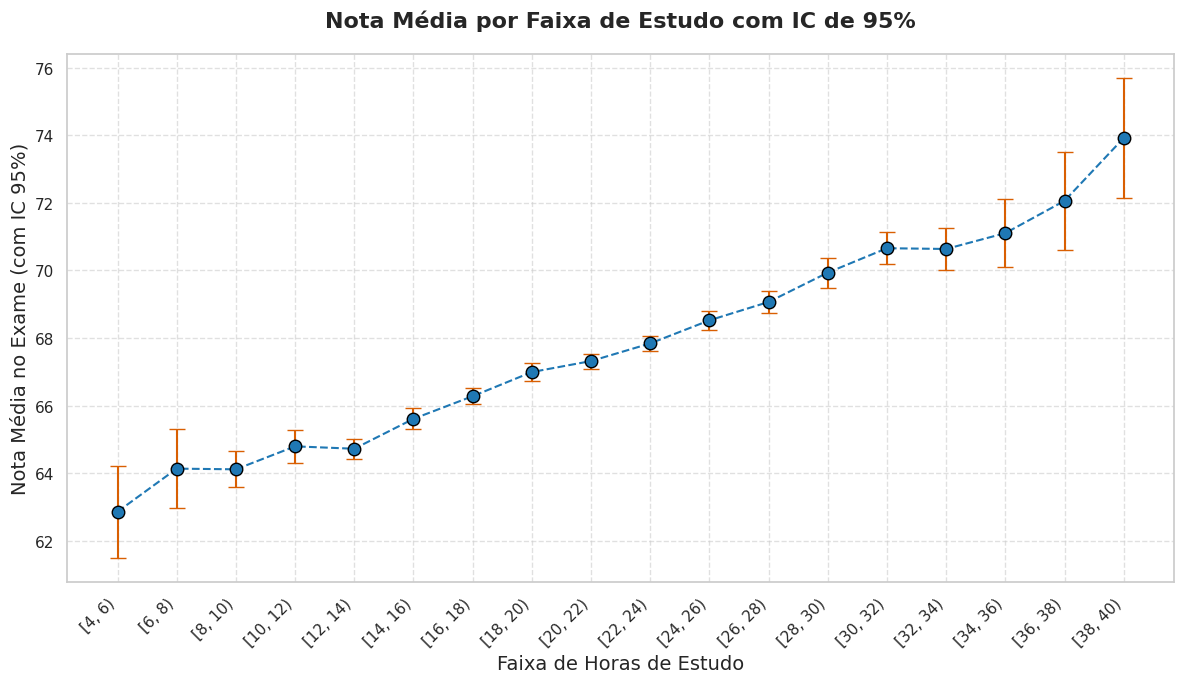

In [ ]:
df_ic = melhor_analise['df_ic']

# Distância entre a Média e o Limite Inferior
yerr_inferior = df_ic['Media'] - df_ic['IC_Inferior']
# Distância entre o Limite Superior e a Média
yerr_superior = df_ic['IC_Superior'] - df_ic['Media']
# Formato exigido pela função plt.errorbar: [Inferior, Superior]
yerr = [yerr_inferior, yerr_superior]

plt.figure(figsize=(12, 7))
# Gráfico de Dispersão com Barras de Erro
plt.errorbar(
    x=df_ic.index,                          # O eixo X são os nomes dos bins
    y=df_ic['Media'],                       # O eixo Y são as Médias
    yerr=yerr,                              # As barras de erro calculadas
    fmt='o',                                # Formato do marcador: 'o' para círculo
    capsize=6,                              # Tamanho das "tampas" das barras
    color='#1f78b4',                        # Cor dos pontos e barras
    ecolor='#d95f02',                       # Cor específica para a barra de erro
    markerfacecolor='#1f78b4',              # Cor de preenchimento do ponto
    markeredgecolor='black',
    markersize=9,
    linestyle='--'                          # Linha tracejada conectando os pontos
)

plt.title(f'Nota Média por Faixa de Estudo com IC de 95%', fontsize=16, weight='bold', pad=20)
plt.xlabel('Faixa de Horas de Estudo', fontsize=14)
plt.ylabel('Nota Média no Exame (com IC 95%)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### CONCLUSÕES:

- A faixa de 4-10h de estudo não parece alterar a nota do aluno, apesar de que a partir de 10h de estudo a nota começa a aumentar  
- A partir de 30 horas de estudo, a nota não parece aumentar.